In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs('../data/marts', exist_ok=True)
os.makedirs('../exports/archive_static_png', exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (11, 6)

df = pd.read_csv('../data/cleaned/customers_cleaned.csv')
print("Danh sách các cột:", df.columns.tolist())
df.head()

Danh sách các cột: ['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']


,customer_id,country,age,gender,membership_tier,registration_date,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned
0,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0
1,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0
2,C00003,United States,43,Female,Gold,2026-02-08,4,195.37,42.74,0,Home & Kitchen,Mobile,PayPal,Referral,0,4.8,0,0,1,0
3,C00004,United States,41,Male,Free,2025-03-19,6,99.45,15.61,6,Electronics,Desktop,PayPal,Organic Search,2,4.2,0,8,1,0
4,C00005,France,37,Other,Platinum,2024-09-10,36,2593.21,79.09,161,Clothing & Apparel,Tablet,Debit Card,Social Media,9,4.0,4,5,1,0


In [2]:
# Tự động tìm chính xác tên cột channel và cột churn
channel_col = [c for c in df.columns if 'channel' in c.lower()][0]
churn_col = [c for c in df.columns if 'churn' in c.lower()][0]
print(f"Đang sử dụng cột kênh: '{channel_col}' | cột churn: '{churn_col}'")

# Nếu cột churn là chữ ('Yes'/'No'), tự động chuyển về 1/0
if df[churn_col].dtype == 'object':
    df[churn_col] = df[churn_col].str.strip().str.lower().map({'yes': 1, 'no': 0, 'true': 1, 'false': 0})

# Tổng hợp số liệu theo từng kênh
churn_by_channel = df.groupby(channel_col).agg(
    Tong_KH=(churn_col, 'count'),
    So_KH_Roi_Bo=(churn_col, 'sum')
).reset_index()

churn_by_channel['So_KH_O_Lai'] = churn_by_channel['Tong_KH'] - churn_by_channel['So_KH_Roi_Bo']
churn_by_channel['Ty_Le_Churn_%'] = (churn_by_channel['So_KH_Roi_Bo'] / churn_by_channel['Tong_KH'] * 100).round(2)

# Sắp xếp giảm dần theo tỷ lệ churn
churn_by_channel = churn_by_channel.sort_values(by='Ty_Le_Churn_%', ascending=False).reset_index(drop=True)

# Hiển thị bảng kết quả
display(churn_by_channel)

# Xuất bảng kết quả ra file CSV để bàn giao
churn_by_channel.to_csv('../data/marts/cau4_churn_by_channel.csv', index=False, encoding='utf-8-sig')
print("Đã xuất bảng kết quả: data/marts/cau4_churn_by_channel.csv")

Đang sử dụng cột kênh: 'acquisition_channel' | cột churn: 'churned'


,acquisition_channel,Tong_KH,So_KH_Roi_Bo,So_KH_O_Lai,Ty_Le_Churn_%
0,Referral,473,47,426,9.94
1,Direct,826,79,747,9.56
2,Social Media,1758,163,1595,9.27
3,Email Campaign,1494,135,1359,9.04
4,Paid Ad,1255,113,1142,9.00
5,Organic Search,2194,178,2016,8.11


Đã xuất bảng kết quả: data/marts/cau4_churn_by_channel.csv


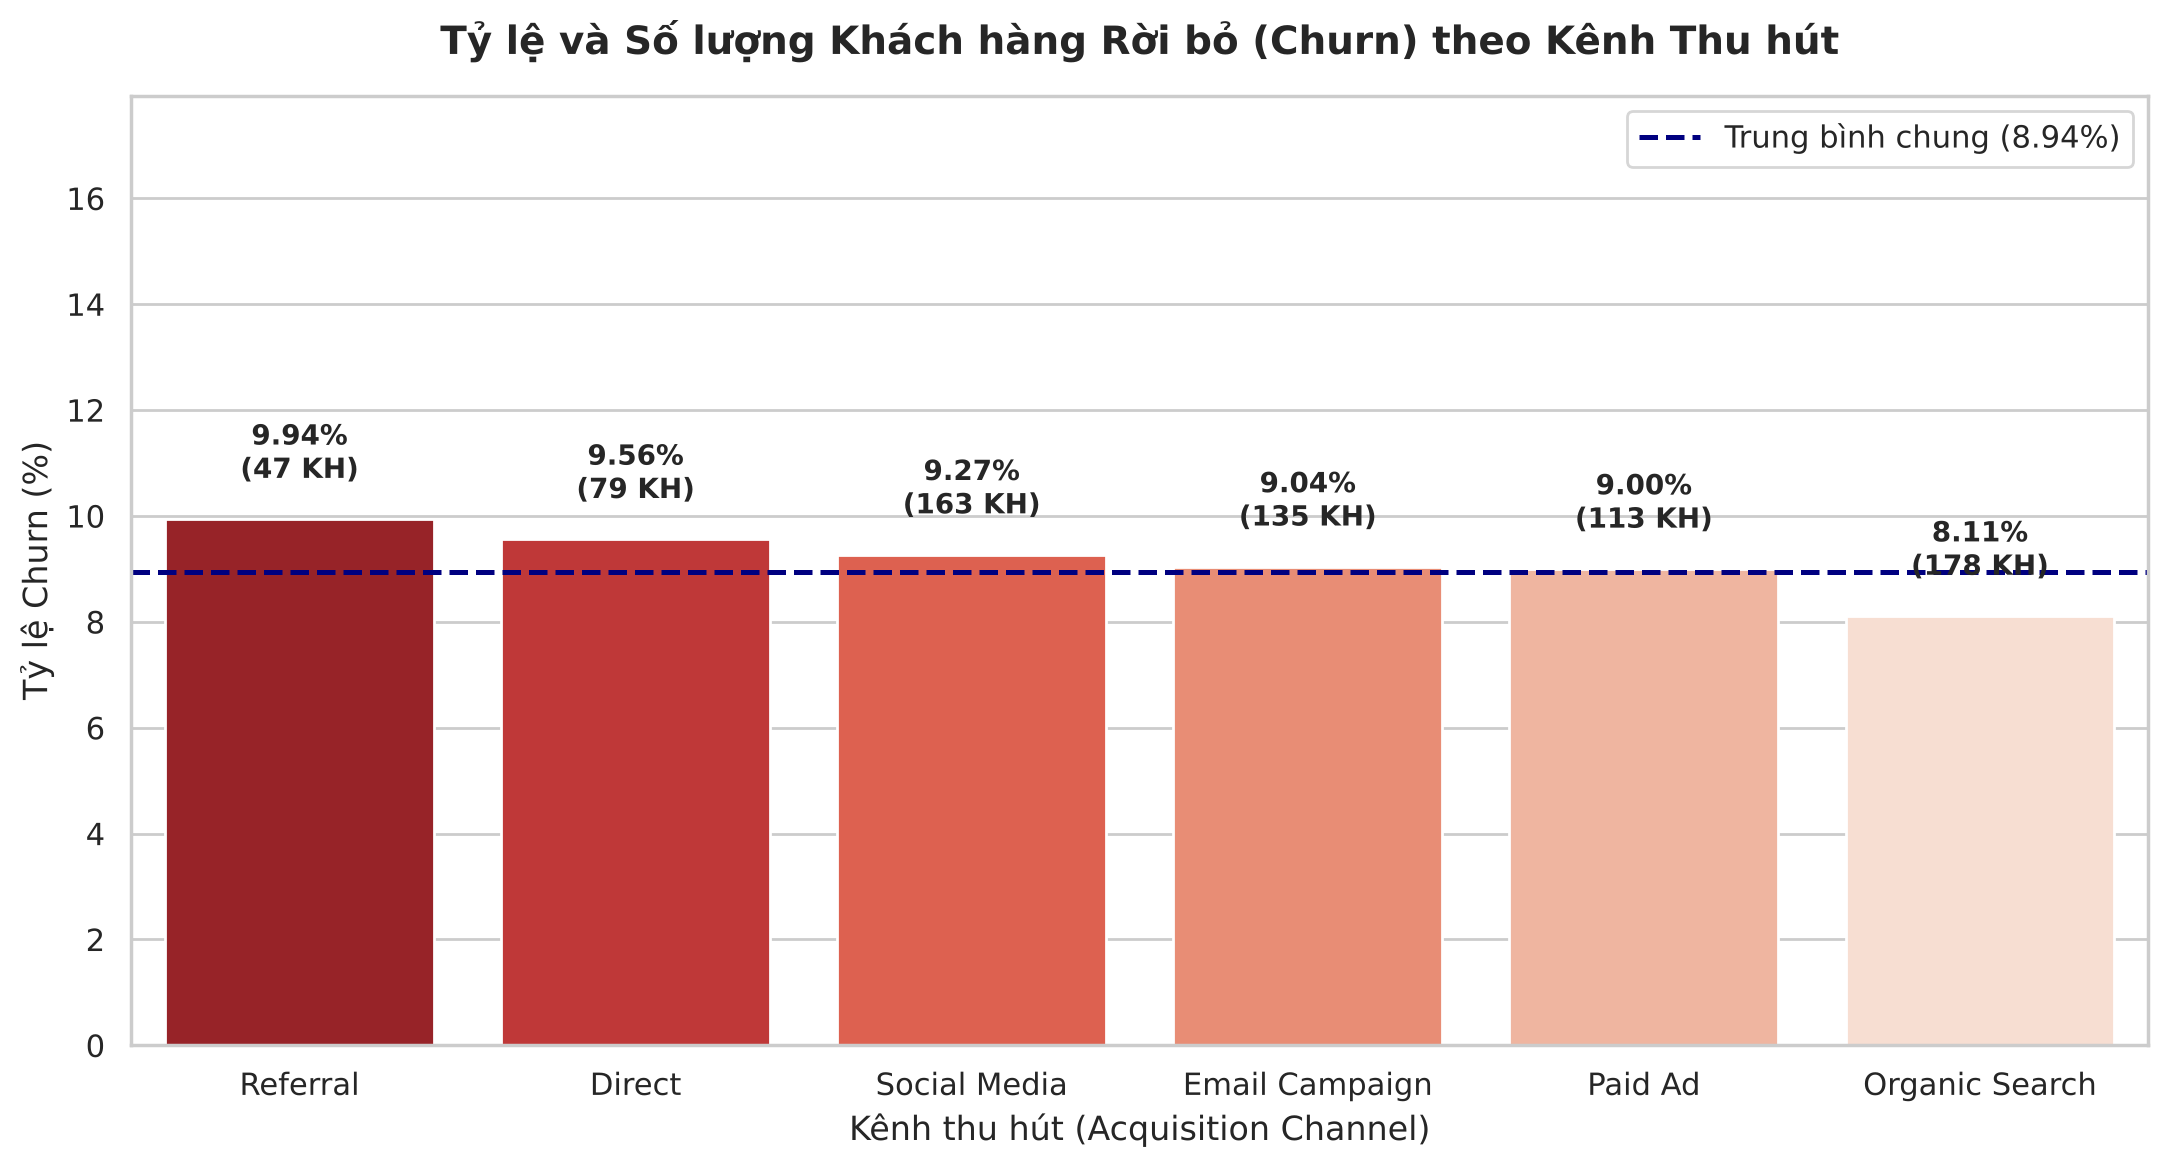

Đã xuất biểu đồ: exports/archive_static_png/cau4_churn_by_channel.png


In [3]:
fig, ax = plt.subplots(figsize=(11, 6))

# Vẽ biểu đồ cột
sns.barplot(
    data=churn_by_channel,
    x=channel_col,
    y='Ty_Le_Churn_%',
    hue=channel_col,
    palette='Reds_r',
    legend=False,
    ax=ax
)

# Đường trung bình chung của toàn bộ khách hàng
avg_churn = df[churn_col].mean() * 100
ax.axhline(avg_churn, color='navy', linestyle='--', linewidth=1.8, label=f'Trung bình chung ({avg_churn:.2f}%)')

# Gắn nhãn % và số lượng KH rời bỏ lên trên mỗi cột
for idx, row in churn_by_channel.iterrows():
    ax.text(
        idx,
        row['Ty_Le_Churn_%'] + 0.6,
        f"{row['Ty_Le_Churn_%']:.2f}%\n({int(row['So_KH_Roi_Bo'])} KH)",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax.set_title('Tỷ lệ và Số lượng Khách hàng Rời bỏ (Churn) theo Kênh Thu hút', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Kênh thu hút (Acquisition Channel)', fontsize=12)
ax.set_ylabel('Tỷ lệ Churn (%)', fontsize=12)
ax.set_ylim(0, churn_by_channel['Ty_Le_Churn_%'].max() + 8)
ax.legend(loc='upper right')

plt.tight_layout()

# Xuất biểu đồ ra file PNG
plt.savefig('../exports/archive_static_png/cau4_churn_by_channel.png', dpi=300)
plt.show()
print("Đã xuất biểu đồ: exports/archive_static_png/cau4_churn_by_channel.png")

In [4]:
# Kiểm định chi-bình phương: tỷ lệ churn có thật sự khác nhau giữa các kênh hay không?
from scipy.stats import chi2_contingency

contingency = pd.crosstab(df[channel_col], df[churn_col])
chi2, p_value, dof, _ = chi2_contingency(contingency)

print(f"Tỷ lệ churn chung: {df[churn_col].mean():.2%} ({int(df[churn_col].sum()):,}/{len(df):,} khách)")
print(f"Chi-square = {chi2:.3f} | bậc tự do = {dof} | p-value = {p_value:.3f}")
print("Kết luận:", "có khác biệt có ý nghĩa thống kê giữa các kênh (p < 0.05)" if p_value < 0.05
      else "chưa có bằng chứng thống kê cho thấy tỷ lệ churn khác nhau giữa các kênh (p >= 0.05)")

Tỷ lệ churn chung: 8.94% (715/8,000 khách)
Chi-square = 3.077 | bậc tự do = 5 | p-value = 0.688
Kết luận: chưa có bằng chứng thống kê cho thấy tỷ lệ churn khác nhau giữa các kênh (p >= 0.05)


## Nhận xét & Kết luận (Câu 4: Phân tích tỷ lệ Churn theo Acquisition Channel)

### 1. Tổng quan
* Tỷ lệ khách hàng rời bỏ (Churn Rate) trung bình trên toàn bộ tập dữ liệu là **8,94%** (715/8.000 khách), tương ứng đường kẻ đứt trên biểu đồ.
* Tỷ lệ churn của 6 kênh thu hút khách hàng (`Referral`, `Direct`, `Social Media`, `Email Campaign`, `Paid Ad`, `Organic Search`) dao động từ **8,11%** đến **9,94%**, chênh lệch chỉ khoảng 1,8 điểm phần trăm. Kiểm định chi-bình phương cho p-value ≈ 0,69 (> 0,05), nên **chưa có bằng chứng thống kê** cho thấy tỷ lệ rời bỏ khác nhau giữa các kênh; thứ tự xếp hạng bên dưới chỉ mang tính mô tả.

### 2. Phân tích chi tiết theo từng kênh
* **Kênh có tỷ lệ Churn cao nhất:** **Referral** đạt **9,94%** (**47** / **473** khách hàng), tiếp theo là **Direct** (**9,56%**) và **Social Media** (**9,27%**). Cả ba chỉ nhỉnh hơn mức chung (8,94%) và Referral có mẫu nhỏ (473 khách) nên ước lượng kém ổn định.
* **Kênh có tỷ lệ Churn thấp nhất:** **Organic Search** chỉ **8,11%** (**178** / **2.194** khách hàng), thấp hơn mức chung khoảng 0,8 điểm phần trăm. **Paid Ad** (**9,00%**) và **Email Campaign** (**9,04%**) gần bằng mức chung.
* Dữ liệu không có thông tin về hành vi mua của từng kênh nên các lý giải như "khách chỉ mua một lần để lấy mã giới thiệu" hay "khách tìm kiếm tự nhiên có nhu cầu rõ ràng" mới chỉ là giả thuyết, cần kiểm chứng thêm.

### 3. Kết luận & Đề xuất sơ bộ
* **Kênh thu hút không phải yếu tố phân biệt mạnh tỷ lệ churn.** Nên ưu tiên các yếu tố giải thích tốt hơn như số ngày chưa mua và số đơn đã mua (xem Câu 10).
* **Theo dõi thêm nhóm `Referral`, `Direct`, `Social Media`:** có thể xem lại quy trình chăm sóc sau mua (onboarding, ưu đãi cho đơn hàng thứ 2) và đo lại khi có thêm dữ liệu.
* **Giữ ổn định `Organic Search`:** kênh có quy mô lớn nhất (2.194 khách) và tỷ lệ churn thấp nhất, tiếp tục đầu tư SEO/nội dung và duy trì Email Marketing cá nhân hóa.